<a href="https://colab.research.google.com/github/ethereal-arko/Handwritten_Digit_Classification_using_ANN/blob/main/Handwritten_Digit_Classification_using_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importing Required Libraries
In this project, we will use several Python libraries for data manipulation, visualization, image processing, and building the Artificial Neural Network.

The required libraries include:
- NumPy: For numerical operations and array manipulation.
- Matplotlib: For visualizing handwritten digit images and model performance.
- Seaborn: For creating an informative confusion matrix.
- TensorFlow and Keras: For building and training the ANN model.
- Scikit-learn: For evaluating the classification model.

In [ ]:
# Importing required libraries

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Setting random seed for reproducibility
tf.keras.utils.set_random_seed(42)

## Loading the MNIST Dataset
The MNIST dataset is a widely used dataset in machine learning and computer vision. It consists of 70,000 grayscale images of handwritten digits ranging from 0 to 9.

Each image has a resolution of 28 × 28 pixels.

The dataset is divided into:
- Training Set: 60,000 images used to train the model.
- Testing Set: 10,000 images used to evaluate the trained model.
We will load the dataset directly from the Keras library.

In [ ]:
# Loading the MNIST dataset

(X_train, Y_train), (X_test, Y_test) = keras.datasets.mnist.load_data()

# Displaying dataset shapes
print("Training Images Shape:", X_train.shape)
print("Training Labels Shape:", Y_train.shape)

print("Testing Images Shape:", X_test.shape)
print("Testing Labels Shape:", Y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images Shape: (60000, 28, 28)
Training Labels Shape: (60000,)
Testing Images Shape: (10000, 28, 28)
Testing Labels Shape: (10000,)


## Dataset Inspection
Before training the model, we will examine the dataset to understand its structure and characteristics.

We will inspect:
- The data types of the image and label arrays.
- The shape of individual images.
- The unique digit labels present in the dataset.
- The minimum and maximum pixel intensity values.
Each image contains 28 × 28 pixels, where pixel values represent grayscale intensity ranging from 0 to 255.

In [ ]:
# Checking data types
print("Training Data Type:", type(X_train))
print("Training Labels Type:", type(Y_train))

# Checking individual image shape
print("\nIndividual Image Shape:", X_train[0].shape)

# Checking unique labels
print("\nUnique Labels:", np.unique(Y_train))

# Checking pixel intensity range
print("\nMinimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

Training Data Type: <class 'numpy.ndarray'>
Training Labels Type: <class 'numpy.ndarray'>

Individual Image Shape: (28, 28)

Unique Labels: [0 1 2 3 4 5 6 7 8 9]

Minimum Pixel Value: 0
Maximum Pixel Value: 255


## Visualizing Handwritten Digit Samples
Visualizing sample images helps us understand how handwritten digits are represented in the dataset.

We will display a collection of sample images along with their corresponding labels.

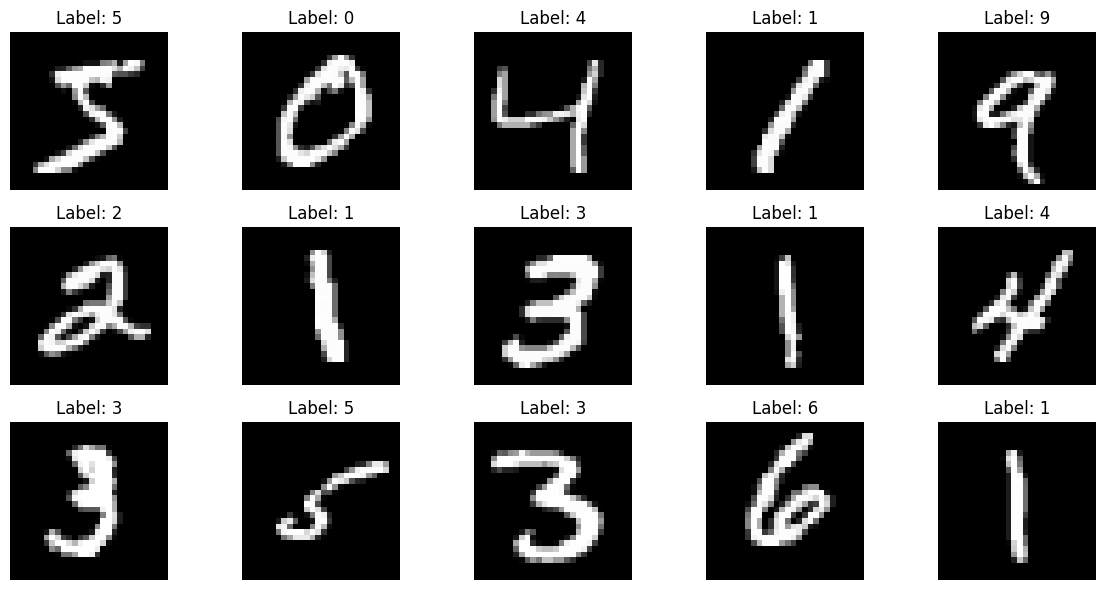

In [ ]:
# Displaying sample handwritten digit images

plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {Y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

## Class Distribution
The MNIST dataset contains 10 different digit classes, ranging from 0 to 9.

We will examine the number of samples belonging to each class to understand the distribution of digits in the training dataset.

Class Distribution:
Digit 0: 5923 samples
Digit 1: 6742 samples
Digit 2: 5958 samples
Digit 3: 6131 samples
Digit 4: 5842 samples
Digit 5: 5421 samples
Digit 6: 5918 samples
Digit 7: 6265 samples
Digit 8: 5851 samples
Digit 9: 5949 samples


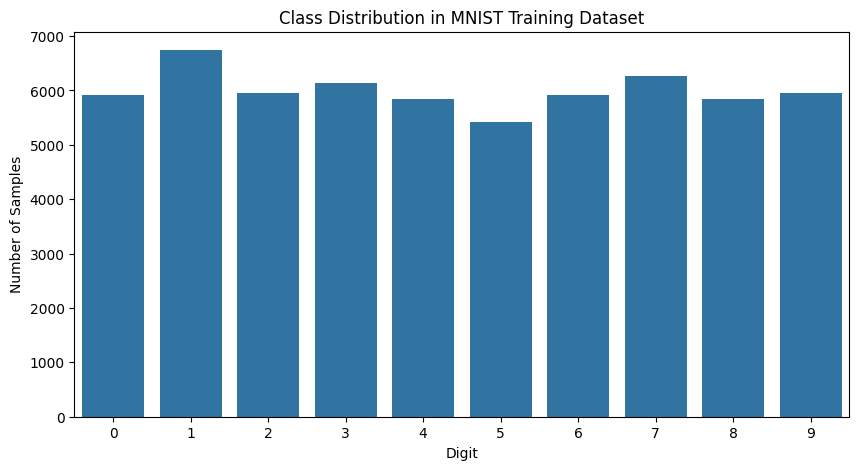

In [ ]:
# Counting samples in each class

unique, counts = np.unique(Y_train, return_counts=True)

print("Class Distribution:")

for label, count in zip(unique, counts):
    print(f"Digit {label}: {count} samples")

# Visualizing class distribution
plt.figure(figsize=(10, 5))

sns.countplot(x=Y_train)

plt.title("Class Distribution in MNIST Training Dataset")
plt.xlabel("Digit")
plt.ylabel("Number of Samples")
plt.show()

## Normalization of Image Pixel Values
The original MNIST images contain pixel intensity values ranging from 0 to 255.

To make the training process more efficient, we will normalize the pixel values by dividing them by 255.

This transforms all pixel values into a range between 0 and 1.

This helps the neural network learn more efficiently by keeping the input values within a smaller numerical range.

In [ ]:
# Normalizing pixel values

X_train = X_train / 255.0
X_test = X_test / 255.0

# Checking normalized pixel values
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nMinimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

print("\nFirst 5 Pixel Values:")
print(X_train[0][0][:5])

Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0

First 5 Pixel Values:
[0. 0. 0. 0. 0.]


## Artificial Neural Network Model Architecture
We will build a Sequential Artificial Neural Network using TensorFlow and Keras to classify handwritten digits into 10 different classes (0–9).

The model will consist of the following layers:

1. Flatten Layer:

Converts each 28 × 28 image into a one-dimensional array containing 784 input features.

2. Hidden Layer:

Contains 50 neurons with the ReLU activation function. It helps the network learn complex patterns and features from handwritten digit images.

3. Output Layer:

Contains 10 neurons with the Softmax activation function. Each neuron represents one digit class (0–9), and Softmax converts the output values into probabilities.

Model Configuration:
- Architecture: Sequential ANN
- Optimizer: Adam
- Loss Function: Sparse Categorical Crossentropy
- Evaluation Metric: Accuracy

In [ ]:
# Building the ANN model

model = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

# Compiling the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Displaying model architecture

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │        39,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,760 (155.31 KB)

 Trainable params: 39,760 (155.31 KB)

 Non-trainable params: 0 (0.00 B)

### Training the Artificial Neural Network

The ANN model is trained using the normalized MNIST training dataset.

A validation split of 10% is used to monitor the model's performance on unseen training samples during training.

The model is trained for 10 epochs with a batch size of 32.

In [ ]:
history = model.fit(
    X_train,
    Y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9075 - loss: 0.3280 - val_accuracy: 0.9568 - val_loss: 0.1558
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9524 - loss: 0.1599 - val_accuracy: 0.9648 - val_loss: 0.1208
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9651 - loss: 0.1173 - val_accuracy: 0.9675 - val_loss: 0.1058
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9724 - loss: 0.0935 - val_accuracy: 0.9692 - val_loss: 0.0989
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9771 - loss: 0.0774 - val_accuracy: 0.9710 - val_loss: 0.0946
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9809 - loss: 0.0657 - val_accuracy: 0.9722 - val_loss: 0.0936
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9840 - loss: 0.0563 - val_accuracy: 0.9730 - val_loss: 0.0946
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9864 - loss: 0.0489 - 

### Visualizing Training and Validation Performance

The training history is visualized to understand how the model learns over multiple epochs.

Two plots are generated:
- Training vs. Validation Accuracy
- Training vs. Validation Loss

These plots help identify the learning progress and possible overfitting.

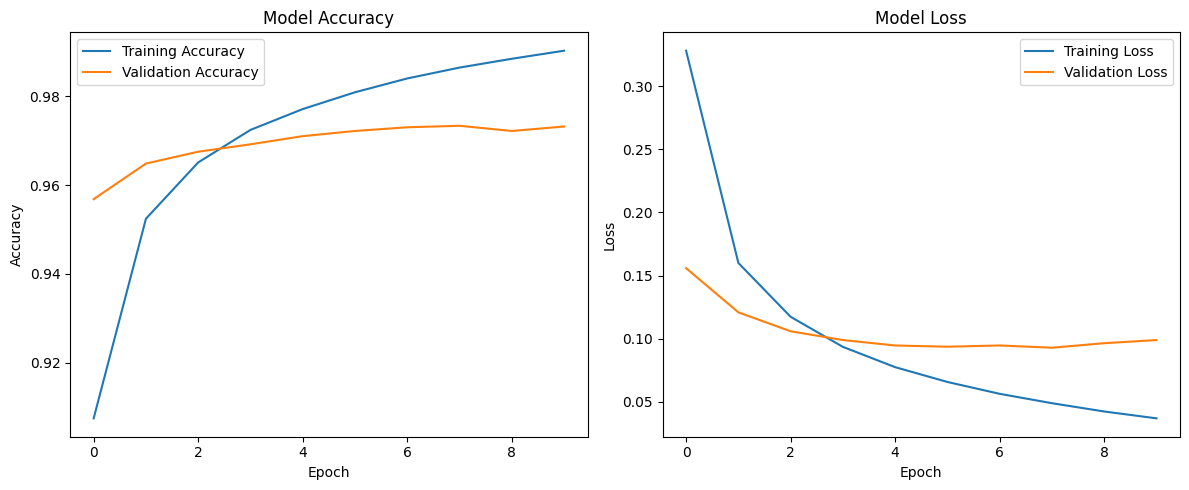

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### Evaluating the Model on Test Data

The trained ANN model is evaluated using the MNIST test dataset.

The test dataset contains 10,000 images that were not used during training.

Test accuracy and test loss are used to measure the model's performance on unseen data.

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, Y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9711 - loss: 0.1012
Test Loss: 0.10123283416032791
Test Accuracy: 0.9710999727249146


### Making Predictions

The trained model generates prediction probabilities for each digit class.

The `argmax()` function selects the class with the highest probability as the predicted digit.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


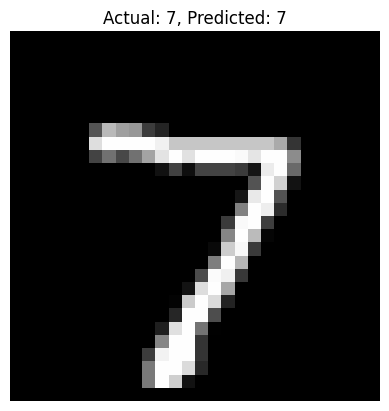

Actual Label: 7
Predicted Label: 7
Prediction Probabilities: [7.5626820e-09 1.8048119e-12 1.4927871e-06 4.2863638e-05 2.8255345e-14
 3.3375752e-08 7.1192760e-14 9.9995500e-01 1.9968660e-07 2.4371636e-07]


In [ ]:
# Generate predictions
y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Display one sample prediction
plt.imshow(X_test[0], cmap='gray')
plt.title(f"Actual: {Y_test[0]}, Predicted: {y_pred[0]}")
plt.axis('off')
plt.show()

print("Actual Label:", Y_test[0])
print("Predicted Label:", y_pred[0])
print("Prediction Probabilities:", y_pred_prob[0])

### Confusion Matrix

A confusion matrix is used to evaluate the classification performance of the model.

It compares the actual labels with the predicted labels for all 10 digit classes.

The diagonal values represent correctly classified images, while the off-diagonal values represent misclassifications.

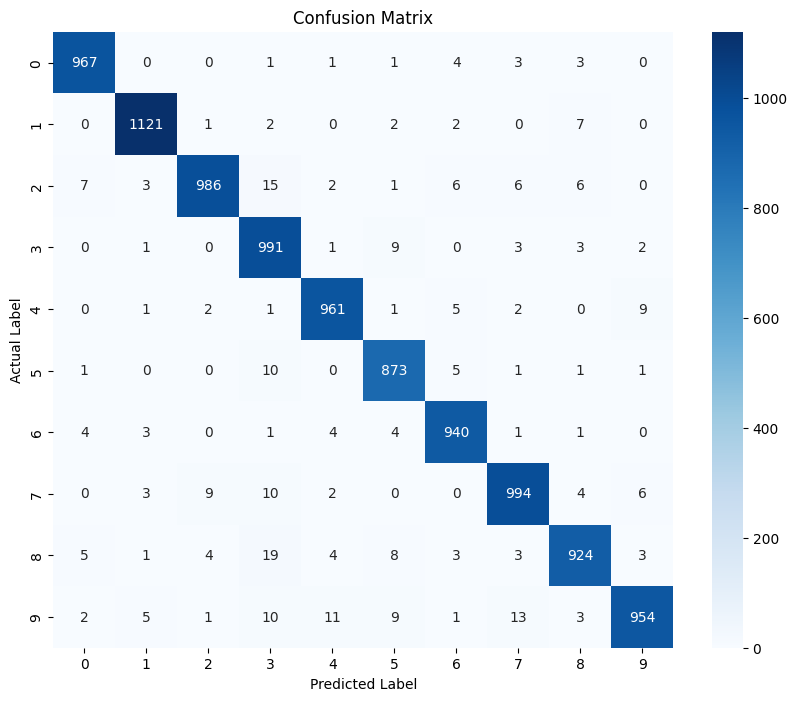

In [ ]:
cm = confusion_matrix(Y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

### Classification Report

The classification report provides a detailed evaluation of the model's performance for each digit class.

It includes the following metrics:

- Precision: The proportion of correctly predicted samples among all samples predicted as a particular class.
- Recall: The proportion of correctly predicted samples among all actual samples of a particular class.
- F1-score: The harmonic mean of precision and recall.
- Support: The total number of actual samples in each class.

In [ ]:
print(classification_report(Y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9807    0.9867    0.9837       980
           1     0.9851    0.9877    0.9864      1135
           2     0.9831    0.9554    0.9690      1032
           3     0.9349    0.9812    0.9575      1010
           4     0.9746    0.9786    0.9766       982
           5     0.9615    0.9787    0.9700       892
           6     0.9731    0.9812    0.9771       958
           7     0.9688    0.9669    0.9679      1028
           8     0.9706    0.9487    0.9595       974
           9     0.9785    0.9455    0.9617      1009

    accuracy                         0.9711     10000
   macro avg     0.9711    0.9711    0.9709     10000
weighted avg     0.9713    0.9711    0.9711     10000



### Predicting Custom Handwritten Digits

The trained ANN model is used to predict a digit from a custom handwritten image.

The uploaded image is preprocessed to match the MNIST dataset format:

- Convert the image to grayscale.
- Invert the image if necessary.
- Crop the digit and resize it while maintaining its aspect ratio.
- Place the digit on a 28×28 black canvas.
- Normalize pixel values between 0 and 1.

Finally, the processed image is passed to the trained model for prediction.

Saving MNIST_digit.png to MNIST_digit (1).png


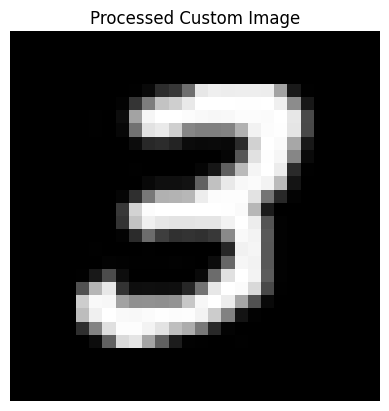

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Predicted Digit: 3
Prediction Confidence: 100.0 %


In [ ]:
from google.colab import files
from PIL import Image, ImageOps

# Upload a handwritten digit image
uploaded = files.upload()
image_path = next(iter(uploaded))

# Load and preprocess the image
image = Image.open(image_path).convert('L')
image = ImageOps.autocontrast(image)

image_array = np.array(image)

# Invert image if the background is light
if image_array.mean() > 127:
    image_array = 255 - image_array

# Crop the digit
binary = image_array > 30

if not np.any(binary):
    raise ValueError("No digit detected in the uploaded image.")

rows = np.where(binary.any(axis=1))[0]
cols = np.where(binary.any(axis=0))[0]

cropped = image_array[
    rows[0]:rows[-1] + 1,
    cols[0]:cols[-1] + 1
]

# Resize while maintaining aspect ratio
digit_image = Image.fromarray(cropped)
digit_image.thumbnail((20, 20), Image.Resampling.LANCZOS)

# Place digit at the center of a 28x28 black canvas
canvas = Image.new('L', (28, 28), 0)

x_offset = (28 - digit_image.width) // 2
y_offset = (28 - digit_image.height) // 2

canvas.paste(digit_image, (x_offset, y_offset))

# Normalize and reshape
input_image = np.array(canvas) / 255.0
input_image = input_image.reshape(1, 28, 28)

# Display processed image
plt.imshow(input_image[0], cmap='gray')
plt.title("Processed Custom Image")
plt.axis('off')
plt.show()

# Predict the digit
prediction = model.predict(input_image)
predicted_digit = np.argmax(prediction)

print("Predicted Digit:", predicted_digit)
print("Prediction Confidence:", round(float(np.max(prediction)) * 100, 2), "%")